# Evaluation of caregiving-experience classification

This notebook reproduces the dissertation evaluation from the original pressure CSV files and the current participant-answer manifest.

**Primary target:** the direct response to whether the participant cared for babies or young children during the last five years. Parent status, experience with a crying baby, handedness, task and reported soothing action are contextual variables, not alternative target labels.

The notebook preserves the raw CSV files, uses participant-separated validation, excludes channel 37 only from derived features, and reports results transparently rather than selecting a favourable model after testing.

## Analysis design

- All trials are restricted to a common 29.75-second window.
- Signed baseline-adjusted values are retained in the source files; processed contact intensity is clipped at zero.
- Noise thresholds are estimated from the dedicated no-touch recording.
- Fourteen interpretable intensity, contact, rhythm, dynamics and spatial features are extracted.
- Repetition stability is assessed with Spearman correlation.
- Task differences use Friedman tests with Benjamini-Hochberg correction.
- Experience-group comparisons use Mann-Whitney tests with correction within each task.
- Logistic regression and a constrained random forest use leave-one-participant-out validation.
- **Seven classification experiments** are evaluated: each single task (HOLD, NATURAL, PAT), all tasks combined (ALL), and three pairwise combinations (HOLD+NATURAL, HOLD+PAT, NATURAL+PAT).
- Logistic regression is compared with 200 participant-label permutations for every experiment.

## 1. Import the required Python tools

In [2]:
"""Reproducible evaluation for the sensorised infant-doll dissertation.

Primary outcome: direct response to recent caregiving within five years.
Raw CSV files are read-only. All trials are truncated to a common 29.75 s window.
"""
from __future__ import annotations

from pathlib import Path
import json
import re
import warnings

import numpy as np
import pandas as pd
from scipy.signal import find_peaks, periodogram
from scipy.stats import friedmanchisquare, mannwhitneyu, spearmanr
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score, balanced_accuracy_score, confusion_matrix, f1_score,
    precision_score, recall_score, roc_auc_score,
)
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.svm import LinearSVC

warnings.filterwarnings("ignore", category=RuntimeWarning)

## 2. Set the file paths and analysis parameters

In [3]:
DATA_DIR = Path(r"C:\download\sensor data\baby data")
PROJECT_DIR = Path(r"C:\Users\q8x7u\Documents\dissertation\Dissertation for job application")
MANIFEST = PROJECT_DIR / "experiment" / "participants answer" / "answer manifest 1.xlsx"
OUT_DIR = PROJECT_DIR / "analysis" / "evaluation_outputs_svm"
OUT_DIR.mkdir(parents=True, exist_ok=True)

WINDOW_S = 29.75
RESAMPLE_HZ = 100.0
EPS = 1e-9
VALID_CHANNELS = [i for i in range(42) if i != 37]
LEFT = [i for i in VALID_CHANNELS if i % 7 <= 2]
CENTER = [i for i in VALID_CHANNELS if 3 <= i % 7 <= 4]
RIGHT = [i for i in VALID_CHANNELS if i % 7 >= 5]

FEATURES = [
    "mean_total", "std_total", "p95_total", "max_total", "contact_fraction",
    "mean_active", "max_active", "peak_rate_hz", "interpeak_cv",
    "dominant_frequency_hz", "mean_abs_slope", "p95_abs_slope",
    "centre_share", "centroid_path_grid_per_s",
    # lr_asymmetry and bilateral_correlation excluded: require confirmed
    # left-right sensor orientation which could not be reliably established,
    # and no supporting reference was identified in the caregiving-touch literature.
]

## 3. Define how labels and recording names are read

In [4]:
def load_labels() -> tuple[dict[str, int], dict[str, int], pd.DataFrame]:
    m = pd.read_excel(MANIFEST, sheet_name="Sheet1", skiprows=[1])
    m["id"] = m["id"].astype(str).str.lower().str.strip()
    label_col = "have you cared for babies or young children in the last 5 yrs?"
    direct = {}
    for _, row in m.iterrows():
        value = str(row[label_col]).strip().lower()
        if value in {"yes", "no"}:
            direct[row["id"]] = int(value == "yes")
    sensitivity = dict(direct)
    return direct, sensitivity, m


def participant_files() -> list[Path]:
    return sorted(p for p in DATA_DIR.glob("*.csv") if re.search(r"p\d{2}", p.name, re.I))


def parse_file(path: Path) -> tuple[str, str, int]:
    pid = re.search(r"(p\d{2})", path.name, re.I).group(1).lower()
    upper = path.name.upper()
    if "NATURAL" in upper:
        task = "NATURAL"
    elif "PAT" in upper:
        task = "PAT"
    elif "HOLD" in upper:
        task = "HOLD"
    else:
        raise ValueError(f"Cannot identify task: {path.name}")
    m = re.search(r"_R(\d+)", upper)
    repeat = int(m.group(1)) if m else 1
    return pid, task, repeat

### Verify the current participant labels

In [5]:
direct_labels, sensitivity_labels, manifest = load_labels()

label_column = 'have you cared for babies or young children in the last 5 yrs?'
label_audit = manifest[['id', label_column]].copy()
label_audit['analysis_label'] = label_audit['id'].map(direct_labels)
label_audit['analysis_group'] = label_audit['analysis_label'].map({
    0: 'No recent experience',
    1: 'Recent experience',
})

display(label_audit)
print('Group counts:', label_audit['analysis_group'].value_counts(dropna=False).to_dict())
print('Missing direct labels:', label_audit.loc[
    label_audit['analysis_label'].isna(), 'id'
].tolist())

,id,have you cared for babies or young children in the last 5 yrs?,analysis_label,analysis_group
0,p01,yes,1,Recent experience
1,p02,no,0,No recent experience
2,p03,no,0,No recent experience
3,p04,no,0,No recent experience
4,p05,yes,1,Recent experience
5,p06,no,0,No recent experience
6,p07,no,0,No recent experience
7,p08,no,0,No recent experience
8,p09,yes,1,Recent experience
9,p10,yes,1,Recent experience


Group counts: {'No recent experience': 11, 'Recent experience': 9}
Missing direct labels: []


## 4. Define the no touch threshold and smoothing methods

In [6]:
def noise_thresholds() -> np.ndarray:
    p = next(DATA_DIR.glob("*baseline no touch pilot study.csv"))
    d = pd.read_csv(p)
    d = d[d["time"] <= WINDOW_S * 1000]
    x = np.maximum(d[[f"pressValues{i}" for i in range(42)]].to_numpy(float), 0)
    return np.maximum(2.0, np.quantile(x, 0.995, axis=0))


def smooth(x: np.ndarray, width: int = 11) -> np.ndarray:
    return pd.Series(x).rolling(width, center=True, min_periods=1).mean().to_numpy()

### Calculate the no touch threshold for each channel

In [7]:
thresholds = noise_thresholds()

threshold_table = pd.DataFrame({
    'channel': range(len(thresholds)),
    'noise_threshold': thresholds,
})

display(threshold_table)

,channel,noise_threshold
0,0,2.0
1,1,2.0
2,2,2.0
3,3,2.0
4,4,2.0
5,5,2.0
6,6,2.0
7,7,2.0
8,8,2.0
9,9,2.0


## 5. Define how features are extracted from one recording

In [8]:
def extract_features(path: Path, thresholds: np.ndarray) -> dict:
    pid, task, repeat = parse_file(path)
    d = pd.read_csv(path)
    d = d[d["time"] <= WINDOW_S * 1000].copy()
    if d.empty:
        raise ValueError(f"No samples in common window: {path.name}")
    time_s = d["time"].to_numpy(float) / 1000.0
    values = np.maximum(d[[f"pressValues{i}" for i in range(42)]].to_numpy(float), 0)
    values[:, 37] = 0.0
    valid = values[:, VALID_CHANNELS]
    total = valid.sum(axis=1)
    active = (values[:, VALID_CHANNELS] > thresholds[VALID_CHANNELS]).sum(axis=1)

    grid_t = np.arange(time_s[0], min(time_s[-1], WINDOW_S), 1.0 / RESAMPLE_HZ)
    total_r = smooth(np.interp(grid_t, time_s, total))
    left_r = smooth(np.interp(grid_t, time_s, values[:, LEFT].mean(axis=1)))
    centre_r = smooth(np.interp(grid_t, time_s, values[:, CENTER].mean(axis=1)))
    right_r = smooth(np.interp(grid_t, time_s, values[:, RIGHT].mean(axis=1)))

    no_touch_sd = max(float(np.std(total_r[total_r <= np.quantile(total_r, 0.25)])), 1.0)
    prominence = max(3.0 * no_touch_sd, 0.10 * max(float(np.quantile(total_r, 0.95)), 1.0))
    peaks, _ = find_peaks(total_r, distance=int(0.25 * RESAMPLE_HZ), prominence=prominence)
    intervals = np.diff(grid_t[peaks]) if len(peaks) >= 2 else np.array([])
    interpeak_cv = float(np.std(intervals) / (np.mean(intervals) + EPS)) if len(intervals) >= 2 else np.nan

    if np.std(total_r) > EPS:
        freq, power = periodogram(total_r - np.mean(total_r), fs=RESAMPLE_HZ)
        band = (freq >= 0.2) & (freq <= 5.0)
        dominant = float(freq[band][np.argmax(power[band])]) if np.any(band) else np.nan
    else:
        dominant = np.nan

    slope = np.gradient(total_r, 1.0 / RESAMPLE_HZ)
    regional_sum = left_r + centre_r + right_r
    lr_asym = float(np.mean((left_r - right_r) / (left_r + right_r + EPS)))
    centre_share = float(np.mean(centre_r / (regional_sum + EPS)))
    bilateral = float(np.corrcoef(left_r, right_r)[0, 1]) if np.std(left_r) > EPS and np.std(right_r) > EPS else np.nan

    coords = np.array([(i % 7, i // 7) for i in VALID_CHANNELS], dtype=float)
    valid_r = np.column_stack([
        smooth(np.interp(grid_t, time_s, values[:, i])) for i in VALID_CHANNELS
    ])
    centroid_weights = np.where(valid_r > thresholds[VALID_CHANNELS], valid_r, 0.0)
    denom = centroid_weights.sum(axis=1)
    cx = np.divide(centroid_weights @ coords[:, 0], denom,
                   out=np.full(len(grid_t), np.nan), where=denom > 0)
    cy = np.divide(centroid_weights @ coords[:, 1], denom,
                   out=np.full(len(grid_t), np.nan), where=denom > 0)
    good = np.isfinite(cx) & np.isfinite(cy)
    if good.sum() >= 2:
        cx_s = smooth(cx[good], width=21); cy_s = smooth(cy[good], width=21)
        path_distance = np.sqrt(np.diff(cx_s) ** 2 + np.diff(cy_s) ** 2).sum()
        path_rate = float(path_distance / max(grid_t[good][-1] - grid_t[good][0], EPS))
    else:
        path_rate = np.nan

    return {
        "participant": pid, "task": task, "repeat": repeat, "file": path.name,
        "samples": len(d), "duration_s": float(time_s[-1] - time_s[0]),
        "mean_total": float(np.mean(total)), "std_total": float(np.std(total)),
        "p95_total": float(np.quantile(total, 0.95)), "max_total": float(np.max(total)),
        "contact_fraction": float(np.mean(active > 0)),
        "mean_active": float(np.mean(active)), "max_active": float(np.max(active)),
        "peak_rate_hz": float(len(peaks) / max(grid_t[-1] - grid_t[0], EPS)),
        "interpeak_cv": interpeak_cv, "dominant_frequency_hz": dominant,
        "mean_abs_slope": float(np.mean(np.abs(slope))),
        "p95_abs_slope": float(np.quantile(np.abs(slope), 0.95)),
        "lr_asymmetry": lr_asym, "centre_share": centre_share,
        "bilateral_correlation": bilateral,
        "centroid_path_grid_per_s": path_rate,
    }

### Extract and save features from every participant recording

In [9]:
recording_files = participant_files()

features = pd.DataFrame([
    extract_features(path, thresholds)
    for path in recording_files
])

features['direct_label'] = features['participant'].map(direct_labels)
features['sensitivity_label'] = features['participant'].map(sensitivity_labels)
features.to_csv(OUT_DIR / 'trial_features.csv', index=False)

print('Files processed:', len(recording_files))
print('Participants:', features['participant'].nunique())
print('Task counts:', features['task'].value_counts().to_dict())

Files processed: 100
Participants: 20
Task counts: {'PAT': 40, 'NATURAL': 40, 'HOLD': 20}


## 6. Define the statistical comparison methods

In [10]:
def bh_adjust(pvalues):
    p = np.asarray(pvalues, float)
    order = np.argsort(p)
    ranked = p[order]
    adjusted = np.minimum.accumulate((ranked * len(p) / np.arange(1, len(p) + 1))[::-1])[::-1]
    out = np.empty_like(adjusted); out[order] = np.minimum(adjusted, 1.0)
    return out


def group_feature_comparisons(frame, labels):
    rows = []
    d = frame[frame.participant.isin(labels)].copy()
    d["label"] = d.participant.map(labels)
    participant_task = d.groupby(["participant", "task", "label"])[FEATURES].mean().reset_index()
    for task in ["HOLD", "NATURAL", "PAT"]:
        sub = participant_task[participant_task.task == task]
        for feature in FEATURES:
            no = sub[sub.label == 0][feature].dropna().to_numpy()
            yes = sub[sub.label == 1][feature].dropna().to_numpy()
            if len(no) < 2 or len(yes) < 2:
                continue
            u, p = mannwhitneyu(yes, no, alternative="two-sided")
            delta = 2.0 * u / (len(yes) * len(no)) - 1.0
            rows.append({"task": task, "feature": feature, "n_no": len(no), "n_yes": len(yes),
                         "median_no": float(np.median(no)), "median_yes": float(np.median(yes)),
                         "cliffs_delta_experienced_minus_no": float(delta), "p_unadjusted": float(p)})
    out = pd.DataFrame(rows)
    out["p_bh_within_task"] = out.groupby("task")["p_unadjusted"].transform(lambda x: bh_adjust(x.to_numpy()))
    return out


def task_feature_comparisons(frame):
    participant_task = frame.groupby(["participant", "task"])[FEATURES].mean().reset_index()
    rows = []
    for feature in FEATURES:
        wide = participant_task.pivot(index="participant", columns="task", values=feature).dropna()
        if not {"HOLD", "NATURAL", "PAT"}.issubset(wide.columns) or len(wide) < 4:
            continue
        stat, p = friedmanchisquare(wide["HOLD"], wide["NATURAL"], wide["PAT"])
        rows.append({"feature": feature, "n": len(wide), "friedman_chi2": float(stat),
                     "p_unadjusted": float(p), "median_hold": float(wide.HOLD.median()),
                     "median_natural": float(wide.NATURAL.median()), "median_pat": float(wide.PAT.median())})
    out = pd.DataFrame(rows)
    out["p_bh"] = bh_adjust(out["p_unadjusted"].to_numpy())
    return out.sort_values("p_bh")


def repeat_stability(frame, labels):
    rows = []
    d = frame[frame["participant"].isin(labels)]
    for task in ["NATURAL", "PAT"]:
        sub = d[d.task == task]
        for feature in FEATURES:
            wide = sub.pivot(index="participant", columns="repeat", values=feature).dropna()
            if 1 in wide.columns and 2 in wide.columns and len(wide) >= 4:
                rho, p = spearmanr(wide[1], wide[2])
                rows.append({"task": task, "feature": feature, "n": len(wide), "spearman_rho": rho, "p": p})
    return pd.DataFrame(rows)

### Calculate repetition stability

In [11]:
stability = repeat_stability(features, direct_labels)
stability.to_csv(OUT_DIR / 'repeat_stability.csv', index=False)

stability_summary = (
    stability.groupby('task')['spearman_rho']
    .agg(['median', 'min', 'max'])
)

display(stability_summary)

,median,min,max
task,,,
NATURAL,0.634586,-0.119650,0.854135
PAT,0.879235,-0.115332,0.944361


### Compare features across holding, natural soothing and patting

In [12]:
task_comparisons = task_feature_comparisons(features)
task_comparisons.to_csv(
    OUT_DIR / 'task_feature_comparisons.csv',
    index=False,
)

display(task_comparisons)

,feature,n,friedman_chi2,p_unadjusted,median_hold,median_natural,median_pat,p_bh
9,dominant_frequency_hz,20,19.384615,0.000062,0.235294,0.352941,0.756303,0.000865
2,p95_total,20,16.545455,0.000255,21.500000,16.500000,9.250000,0.001788
7,peak_rate_hz,20,15.518987,0.000427,0.050437,0.344654,0.210155,0.001991
5,mean_active,20,12.900000,0.001581,1.642557,0.948038,0.176192,0.004425
1,std_total,20,13.300000,0.001294,5.703598,5.296520,2.641544,0.004425
11,p95_abs_slope,20,11.700000,0.002880,27.506239,48.089015,30.893939,0.006720
0,mean_total,20,10.900000,0.004296,12.830690,7.795783,3.566132,0.008593
6,max_active,20,9.194444,0.010080,4.000000,4.000000,2.750000,0.016438
10,mean_abs_slope,20,9.100000,0.010567,10.959324,15.897287,11.738469,0.016438
3,max_total,20,8.379747,0.015148,30.000000,40.750000,19.750000,0.021207


### Compare participants with and without recent caregiving experience

In [13]:
group_comparisons = group_feature_comparisons(features, direct_labels)
group_comparisons.to_csv(
    OUT_DIR / 'group_feature_comparisons.csv',
    index=False,
)

display(group_comparisons.sort_values(['task', 'p_bh_within_task']))
print(
    'Number significant after correction:',
    int((group_comparisons['p_bh_within_task'] < 0.05).sum()),
)

,task,feature,n_no,n_yes,median_no,median_yes,cliffs_delta_experienced_minus_no,p_unadjusted,p_bh_within_task
0,HOLD,mean_total,11,9,13.321457,12.339922,-0.111111,0.704043,1.000000
1,HOLD,std_total,11,9,5.560753,5.910828,-0.010101,1.000000,1.000000
2,HOLD,p95_total,11,9,19.000000,24.000000,-0.161616,0.568375,1.000000
3,HOLD,max_total,11,9,31.000000,29.000000,-0.121212,0.675823,1.000000
4,HOLD,contact_fraction,11,9,0.847002,0.869185,-0.010101,1.000000,1.000000
5,HOLD,mean_active,11,9,1.675810,1.609304,-0.191919,0.494125,1.000000
6,HOLD,max_active,11,9,4.000000,4.000000,-0.010101,1.000000,1.000000
7,HOLD,peak_rate_hz,11,9,0.033625,0.067249,0.202020,0.460677,1.000000
8,HOLD,interpeak_cv,4,3,0.492013,0.869267,0.666667,0.228571,1.000000
9,HOLD,dominant_frequency_hz,11,9,0.235294,0.268908,0.090909,0.751997,1.000000


Number significant after correction: 0


## 7. Define the participant separated machine learning methods

### Classification experiments

Seven experiments are conducted to test whether restricting or combining task conditions affects caregiving-experience classification performance:

| Experiment | Tasks included | Rationale |
|---|---|---|
| HOLD | Holding only | Neutral baseline; minimal active variation |
| NATURAL | Natural comforting only | Preserves participants' self-selected strategy |
| PAT | Patting only | Constrained; reduced between-group variation expected |
| ALL | All three tasks | Maximum data; task included as feature |
| HOLD+NATURAL | Holding + natural comforting | Removes instructed task to test participant-selected behaviour |
| HOLD+PAT | Holding + patting | Removes open-ended condition |
| NATURAL+PAT | Natural comforting + patting | Removes neutral holding reference |

Task is included as a categorical feature whenever more than one task is used, allowing the model to account for task-level pressure differences.

In [14]:
def make_model(name: str, include_task: bool):
    numeric = Pipeline([
        ("impute", SimpleImputer(strategy="median")),
        ("scale", StandardScaler()),
    ])
    transformers = [("numeric", numeric, FEATURES)]
    if include_task:
        transformers.append(("task", OneHotEncoder(handle_unknown="ignore"), ["task"]))
    prep = ColumnTransformer(transformers)
    if name == "logistic":
        clf = LogisticRegression(C=0.1, penalty="l2", class_weight="balanced",
                                 solver="liblinear", random_state=23)
    elif name == "linear_svm":
        # A fixed, pre-specified linear SVM avoids selecting C on the outer test results.
        # Standardisation is fitted within each participant-separated training fold.
        clf = LinearSVC(C=0.1, class_weight="balanced", dual="auto",
                        max_iter=20000, random_state=23)
    elif name == "forest":
        clf = RandomForestClassifier(n_estimators=500, max_depth=3, min_samples_leaf=2,
                                     max_features="sqrt", class_weight="balanced",
                                     random_state=23, n_jobs=-1)
    else:
        raise ValueError(name)
    return Pipeline([("prepare", prep), ("classifier", clf)])


def logo_predict(frame: pd.DataFrame, labels: dict[str, int], model_name: str, setting: str):
    # Leave one participant out and aggregate repeated-trial scores per participant.
    d = frame[frame["participant"].isin(labels)].copy()

    if setting == "ALL":
        task_list = ["HOLD", "NATURAL", "PAT"]
    elif "+" in setting:
        task_list = [t.strip() for t in setting.split("+")]
        d = d[d["task"].isin(task_list)].copy()
    else:
        task_list = [setting]
        d = d[d["task"] == setting].copy()

    include_task = len(task_list) > 1
    feature_cols = FEATURES + (["task"] if include_task else [])

    participants = sorted(d["participant"].unique())
    scores, truth = {}, {}
    for pid in participants:
        train = d[d["participant"] != pid]
        test = d[d["participant"] == pid]
        y_train = train["participant"].map(labels).to_numpy()
        model = make_model(model_name, include_task=include_task)
        model.fit(train[feature_cols], y_train)

        if model_name == "linear_svm":
            # Decision scores are valid for ROC AUC and avoid probability calibration
            # on this very small training sample. Zero is the SVM class boundary.
            trial_scores = model.decision_function(test[feature_cols])
            scores[pid] = float(np.mean(trial_scores))
        else:
            scores[pid] = float(model.predict_proba(test[feature_cols])[:, 1].mean())
        truth[pid] = labels[pid]

    y = np.array([truth[p] for p in participants])
    score = np.array([scores[p] for p in participants])
    threshold = 0.0 if model_name == "linear_svm" else 0.5
    pred = (score >= threshold).astype(int)
    return participants, y, score, pred


def metrics(y, score, pred):
    cm = confusion_matrix(y, pred, labels=[0, 1])
    return {
        "n": int(len(y)), "accuracy": float(accuracy_score(y, pred)),
        "balanced_accuracy": float(balanced_accuracy_score(y, pred)),
        "precision": float(precision_score(y, pred, zero_division=0)),
        "recall": float(recall_score(y, pred, zero_division=0)),
        "f1": float(f1_score(y, pred, zero_division=0)),
        "roc_auc": float(roc_auc_score(y, score)),
        "confusion_matrix_TN_FP_FN_TP": [int(cm[0, 0]), int(cm[0, 1]),
                                           int(cm[1, 0]), int(cm[1, 1])],
    }


def stratified_bootstrap_ci(y, score, threshold, n_boot=5000):
    rng = np.random.default_rng(23)
    y = np.asarray(y); score = np.asarray(score)
    class0 = np.flatnonzero(y == 0); class1 = np.flatnonzero(y == 1)
    values = []
    for _ in range(n_boot):
        idx = np.concatenate([rng.choice(class0, len(class0), replace=True),
                              rng.choice(class1, len(class1), replace=True)])
        values.append(balanced_accuracy_score(y[idx], (score[idx] >= threshold).astype(int)))
    return [float(x) for x in np.quantile(values, [0.025, 0.975])]


### Define the participant label permutation test

The permutation test shuffles participant-level caregiving labels 200 times and runs the full LOGO evaluation for each shuffle. This produces an empirical null distribution of balanced accuracy values against which the observed result is compared.

**Important:** label shuffling is used only as a chance comparison baseline. The main supervised learning experiment uses the original, unmodified caregiving labels. The permutation test does not change the labels used for any primary classification result.

In [15]:
def permutation_p(frame, labels, setting, model_name, observed, n_perm=200):
    # Shuffle labels at participant level, then repeat the complete outer LOGO analysis.
    rng = np.random.default_rng(23)
    pids = sorted(labels)
    original = np.array([labels[p] for p in pids])
    null = []
    for _ in range(n_perm):
        shuffled = rng.permutation(original)
        permuted = dict(zip(pids, shuffled.tolist()))
        _, y, score, pred = logo_predict(frame, permuted, model_name, setting)
        null.append(balanced_accuracy_score(y, pred))
    null = np.asarray(null)
    return float((1 + np.sum(null >= observed)) / (len(null) + 1)), {
        "permutations": n_perm, "null_mean": float(np.mean(null)),
        "null_p95": float(np.quantile(null, 0.95)),
    }


### Run the machine learning evaluation

In [16]:
results = []
predictions = []

analyses = [('primary_direct_labels', direct_labels)]
if sensitivity_labels != direct_labels:
    analyses.append(('sensitivity_labels', sensitivity_labels))

SETTINGS = ['HOLD', 'NATURAL', 'PAT', 'ALL',
            'HOLD+NATURAL', 'HOLD+PAT', 'NATURAL+PAT']

for analysis_name, analysis_labels in analyses:
    for setting in SETTINGS:
        for model_name in ['logistic', 'linear_svm', 'forest']:
            pids, y, scores, predicted = logo_predict(
                features, analysis_labels, model_name, setting,
            )
            result = {
                'analysis': analysis_name,
                'setting': setting,
                'model': model_name,
                **metrics(y, scores, predicted),
            }
            threshold = 0.0 if model_name == 'linear_svm' else 0.5
            result['balanced_accuracy_ci95_bootstrap'] = stratified_bootstrap_ci(
                y, scores, threshold,
            )

            # Permutation inference is reported for the two primary linear models.
            if model_name in ['logistic', 'linear_svm'] and analysis_name == 'primary_direct_labels':
                p_value, null_result = permutation_p(
                    features, analysis_labels, setting, model_name,
                    result['balanced_accuracy'],
                )
                result['permutation_p'] = p_value
                result.update({f'permutation_{key}': value for key, value in null_result.items()})

            results.append(result)
            predictions.extend({
                'analysis': analysis_name,
                'setting': setting,
                'model': model_name,
                'participant': participant,
                'true_label': int(true_label),
                'decision_score_experienced': float(score),
                'predicted_label': int(predicted_label),
            } for participant, true_label, score, predicted_label in zip(
                pids, y, scores, predicted,
            ))

print('Model evaluations completed:', len(results))


Model evaluations completed: 21


### Save the model results and participant predictions

In [17]:
result_df = pd.DataFrame(results)
prediction_df = pd.DataFrame(predictions)

result_df.to_csv(OUT_DIR / 'model_results.csv', index=False)
prediction_df.to_csv(
    OUT_DIR / 'participant_predictions.csv',
    index=False,
)

display(result_df)

,analysis,setting,model,n,accuracy,balanced_accuracy,precision,recall,f1,roc_auc,confusion_matrix_TN_FP_FN_TP,balanced_accuracy_ci95_bootstrap,permutation_p,permutation_permutations,permutation_null_mean,permutation_null_p95
0,primary_direct_labels,HOLD,logistic,20,0.40,0.393939,0.333333,0.333333,0.333333,0.272727,"[5, 6, 6, 3]","[0.1919191919191919, 0.606060606060606]",0.756219,200.0,0.501944,0.742929
1,primary_direct_labels,HOLD,linear_svm,20,0.50,0.484848,0.428571,0.333333,0.375000,0.363636,"[7, 4, 6, 3]","[0.2828282828282828, 0.696969696969697]",0.567164,200.0,0.492146,0.742424
2,primary_direct_labels,HOLD,forest,20,0.30,0.292929,0.222222,0.222222,0.222222,0.333333,"[4, 7, 7, 2]","[0.10101010101010101, 0.4949494949494949]",NaN,NaN,NaN,NaN
3,primary_direct_labels,NATURAL,logistic,20,0.70,0.696970,0.666667,0.666667,0.666667,0.717172,"[8, 3, 3, 6]","[0.4949494949494949, 0.898989898989899]",0.149254,200.0,0.501338,0.707071
4,primary_direct_labels,NATURAL,linear_svm,20,0.60,0.595960,0.555556,0.555556,0.555556,0.646465,"[7, 4, 4, 5]","[0.3838383838383838, 0.8080808080808081]",0.303483,200.0,0.500000,0.752525
5,primary_direct_labels,NATURAL,forest,20,0.50,0.484848,0.428571,0.333333,0.375000,0.525253,"[7, 4, 6, 3]","[0.2828282828282828, 0.6868686868686869]",NaN,NaN,NaN,NaN
6,primary_direct_labels,PAT,logistic,20,0.55,0.550505,0.500000,0.555556,0.526316,0.474747,"[6, 5, 4, 5]","[0.3282828282828283, 0.7626262626262625]",0.328358,200.0,0.468157,0.707071
7,primary_direct_labels,PAT,linear_svm,20,0.50,0.505051,0.454545,0.555556,0.500000,0.444444,"[5, 6, 4, 5]","[0.29292929292929293, 0.7070707070707071]",0.402985,200.0,0.465328,0.732828
8,primary_direct_labels,PAT,forest,20,0.50,0.484848,0.428571,0.333333,0.375000,0.424242,"[7, 4, 6, 3]","[0.2828282828282828, 0.6868686868686869]",NaN,NaN,NaN,NaN
9,primary_direct_labels,ALL,logistic,20,0.45,0.449495,0.400000,0.444444,0.421053,0.454545,"[5, 6, 5, 4]","[0.23737373737373738, 0.6616161616161615]",0.651741,200.0,0.479318,0.697475


## 8. Save the analysis quality control summary

In [18]:
qc = {
    'participant_files': int(len(features)),
    'participants': int(features['participant'].nunique()),
    'task_counts': features['task'].value_counts().to_dict(),
    'window_s': WINDOW_S,
    'channel_37_excluded': True,
    'direct_labels': direct_labels,
    'direct_group_counts': (
        pd.Series(direct_labels).value_counts().sort_index().to_dict()
    ),
    'missing_direct_labels': sorted(
        set(features['participant']) - set(direct_labels)
    ),
    'sensitivity_labels': sensitivity_labels,
    'noise_thresholds': thresholds.tolist(),
    'repeat_stability_summary': stability_summary.to_dict('index'),
}

with (OUT_DIR / 'analysis_summary.json').open('w', encoding='utf-8') as file:
    json.dump(qc, file, indent=2)

print('Labels:', qc['direct_labels'])
print('Missing labels:', qc['missing_direct_labels'])
print('Task counts:', qc['task_counts'])

Labels: {'p01': 1, 'p02': 0, 'p03': 0, 'p04': 0, 'p05': 1, 'p06': 0, 'p07': 0, 'p08': 0, 'p09': 1, 'p10': 1, 'p11': 0, 'p12': 1, 'p13': 0, 'p14': 0, 'p15': 0, 'p16': 1, 'p17': 0, 'p18': 1, 'p19': 1, 'p20': 1}
Missing labels: []
Task counts: {'PAT': 40, 'NATURAL': 40, 'HOLD': 20}


## 9. Inspect task differences and repetition stability

In [19]:
task_results = pd.read_csv(OUT_DIR / 'task_feature_comparisons.csv')
stability_results = pd.read_csv(OUT_DIR / 'repeat_stability.csv')

display(task_results)
display(stability_summary)
display(stability_results[['task', 'feature', 'n', 'spearman_rho']])

,feature,n,friedman_chi2,p_unadjusted,median_hold,median_natural,median_pat,p_bh
0,dominant_frequency_hz,20,19.384615,0.000062,0.235294,0.352941,0.756303,0.000865
1,p95_total,20,16.545455,0.000255,21.500000,16.500000,9.250000,0.001788
2,peak_rate_hz,20,15.518987,0.000427,0.050437,0.344654,0.210155,0.001991
3,mean_active,20,12.900000,0.001581,1.642557,0.948038,0.176192,0.004425
4,std_total,20,13.300000,0.001294,5.703598,5.296520,2.641544,0.004425
5,p95_abs_slope,20,11.700000,0.002880,27.506239,48.089015,30.893939,0.006720
6,mean_total,20,10.900000,0.004296,12.830690,7.795783,3.566132,0.008593
7,max_active,20,9.194444,0.010080,4.000000,4.000000,2.750000,0.016438
8,mean_abs_slope,20,9.100000,0.010567,10.959324,15.897287,11.738469,0.016438
9,max_total,20,8.379747,0.015148,30.000000,40.750000,19.750000,0.021207


,median,min,max
task,,,
NATURAL,0.634586,-0.119650,0.854135
PAT,0.879235,-0.115332,0.944361


,task,feature,n,spearman_rho
0,NATURAL,mean_total,20,0.854135
1,NATURAL,std_total,20,0.627068
2,NATURAL,p95_total,20,0.750948
3,NATURAL,max_total,20,0.429976
4,NATURAL,contact_fraction,20,0.655639
5,NATURAL,mean_active,20,0.834586
6,NATURAL,max_active,20,0.712456
7,NATURAL,peak_rate_hz,20,0.174454
8,NATURAL,interpeak_cv,12,0.426573
9,NATURAL,dominant_frequency_hz,20,-0.119650


### Feature stability figure

The points below show the Spearman correlation between repetition 1 and repetition 2 for every extracted feature. The dashed vertical lines show the median correlation within each task.

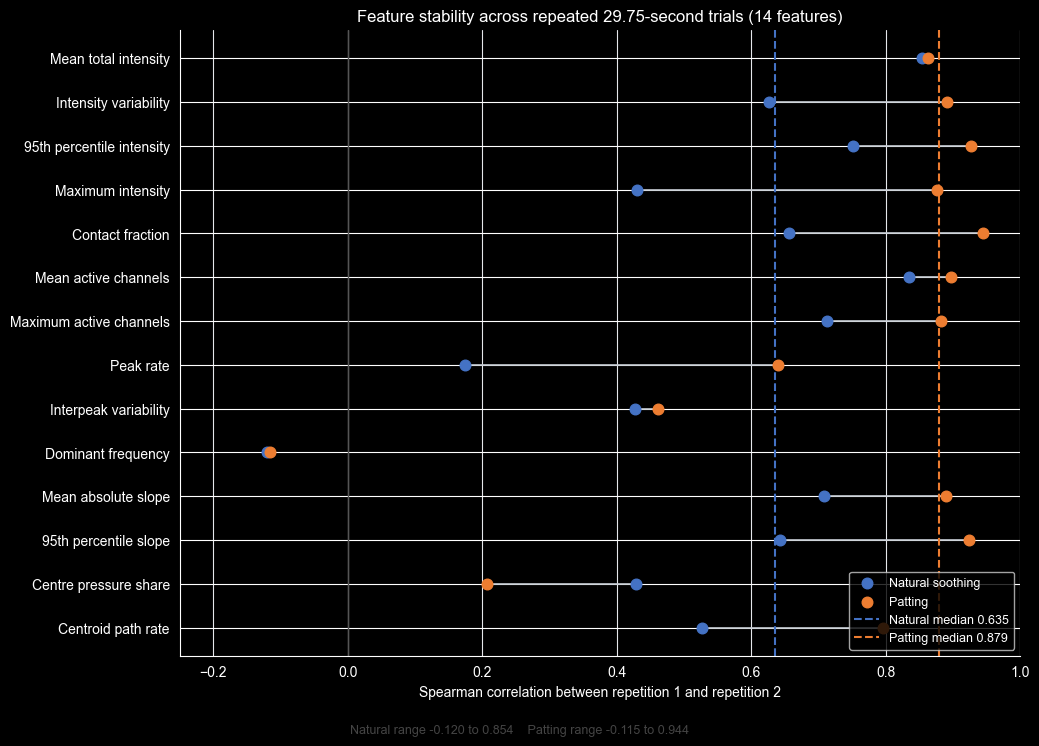

Saved: C:\Users\q8x7u\Documents\dissertation\Dissertation for job application\analysis\evaluation_outputs_svm\repeat_feature_stability.png


In [20]:
import matplotlib.pyplot as plt

OUT_DIR.mkdir(parents=True, exist_ok=True)

feature_order = [
    'mean_total', 'std_total', 'p95_total', 'max_total',
    'contact_fraction', 'mean_active', 'max_active', 'peak_rate_hz',
    'interpeak_cv', 'dominant_frequency_hz', 'mean_abs_slope',
    'p95_abs_slope', 'centre_share', 'centroid_path_grid_per_s'
]

feature_labels = {
    'mean_total': 'Mean total intensity',
    'std_total': 'Intensity variability',
    'p95_total': '95th percentile intensity',
    'max_total': 'Maximum intensity',
    'contact_fraction': 'Contact fraction',
    'mean_active': 'Mean active channels',
    'max_active': 'Maximum active channels',
    'peak_rate_hz': 'Peak rate',
    'interpeak_cv': 'Interpeak variability',
    'dominant_frequency_hz': 'Dominant frequency',
    'mean_abs_slope': 'Mean absolute slope',
    'p95_abs_slope': '95th percentile slope',
    'centre_share': 'Centre pressure share',
    'centroid_path_grid_per_s': 'Centroid path rate'
}

wide = stability_results.pivot(
    index='feature', columns='task', values='spearman_rho'
).loc[feature_order]

fig, ax = plt.subplots(figsize=(10.5, 7.5))
y_positions = range(len(feature_order))

for position, feature in enumerate(feature_order):
    ax.plot(
        [wide.loc[feature, 'NATURAL'], wide.loc[feature, 'PAT']],
        [position, position],
        color='#C7CDD4', linewidth=1.2, zorder=1
    )

ax.scatter(wide['NATURAL'], y_positions, s=58, color='#4472C4',
           label='Natural soothing', zorder=3)
ax.scatter(wide['PAT'],     y_positions, s=58, color='#ED7D31',
           label='Patting',        zorder=3)

natural_median = stability_summary.loc['NATURAL', 'median']
patting_median = stability_summary.loc['PAT', 'median']
ax.axvline(0, color='#555555', linewidth=1)
ax.axvline(natural_median, color='#4472C4', linestyle='--', linewidth=1.5,
           label=f'Natural median {natural_median:.3f}')
ax.axvline(patting_median, color='#ED7D31', linestyle='--', linewidth=1.5,
           label=f'Patting median {patting_median:.3f}')

ax.set_yticks(list(y_positions))
ax.set_yticklabels([feature_labels[f] for f in feature_order])
ax.invert_yaxis()
ax.set_xlim(-0.25, 1.0)
ax.set_xlabel('Spearman correlation between repetition 1 and repetition 2')
ax.set_title('Feature stability across repeated 29.75-second trials (14 features)')
ax.grid(axis='x', color='#E5E7EB', linewidth=0.8)
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.legend(loc='lower right', frameon=True, fontsize=9)

natural_min = stability_summary.loc['NATURAL', 'min']
natural_max = stability_summary.loc['NATURAL', 'max']
patting_min = stability_summary.loc['PAT', 'min']
patting_max = stability_summary.loc['PAT', 'max']
note = (
    f'Natural range {natural_min:.3f} to {natural_max:.3f}    '
    f'Patting range {patting_min:.3f} to {patting_max:.3f}'
)
fig.text(0.5, 0.015, note, ha='center', fontsize=9, color='#444444')
fig.tight_layout(rect=(0, 0.04, 1, 1))

stability_figure_path = OUT_DIR / 'repeat_feature_stability.png'
fig.savefig(stability_figure_path, dpi=200, bbox_inches='tight')
plt.show()
print(f'Saved: {stability_figure_path}')

## 10. Inspect experience group comparisons

In [21]:
group_results = pd.read_csv(OUT_DIR / 'group_feature_comparisons.csv')
display(group_results.sort_values(['task', 'p_bh_within_task']))
print('Number significant after correction:', int((group_results['p_bh_within_task'] < 0.05).sum()))

,task,feature,n_no,n_yes,median_no,median_yes,cliffs_delta_experienced_minus_no,p_unadjusted,p_bh_within_task
0,HOLD,mean_total,11,9,13.321457,12.339922,-0.111111,0.704043,1.000000
1,HOLD,std_total,11,9,5.560753,5.910828,-0.010101,1.000000,1.000000
2,HOLD,p95_total,11,9,19.000000,24.000000,-0.161616,0.568375,1.000000
3,HOLD,max_total,11,9,31.000000,29.000000,-0.121212,0.675823,1.000000
4,HOLD,contact_fraction,11,9,0.847002,0.869185,-0.010101,1.000000,1.000000
5,HOLD,mean_active,11,9,1.675810,1.609304,-0.191919,0.494125,1.000000
6,HOLD,max_active,11,9,4.000000,4.000000,-0.010101,1.000000,1.000000
7,HOLD,peak_rate_hz,11,9,0.033625,0.067249,0.202020,0.460677,1.000000
8,HOLD,interpeak_cv,4,3,0.492013,0.869267,0.666667,0.228571,1.000000
9,HOLD,dominant_frequency_hz,11,9,0.235294,0.268908,0.090909,0.751997,1.000000


Number significant after correction: 0


## 11. Inspect the participant separated machine learning results

In [22]:
model_results = pd.read_csv(OUT_DIR / 'model_results.csv')
primary_results = model_results[model_results['analysis'] == 'primary_direct_labels'].copy()

# Show all experiments sorted by setting and model
cols_to_show = ['setting', 'model', 'n', 'accuracy', 'balanced_accuracy', 'roc_auc',
                'permutation_p', 'confusion_matrix_TN_FP_FN_TP']
available_cols = [c for c in cols_to_show if c in primary_results.columns]
display(primary_results[available_cols].sort_values(['setting', 'model']))

,setting,model,n,accuracy,balanced_accuracy,roc_auc,permutation_p,confusion_matrix_TN_FP_FN_TP
11,ALL,forest,20,0.45,0.439394,0.393939,NaN,"[6, 5, 6, 3]"
10,ALL,linear_svm,20,0.45,0.459596,0.484848,0.567164,"[4, 7, 4, 5]"
9,ALL,logistic,20,0.45,0.449495,0.454545,0.651741,"[5, 6, 5, 4]"
2,HOLD,forest,20,0.30,0.292929,0.333333,NaN,"[4, 7, 7, 2]"
1,HOLD,linear_svm,20,0.50,0.484848,0.363636,0.567164,"[7, 4, 6, 3]"
0,HOLD,logistic,20,0.40,0.393939,0.272727,0.756219,"[5, 6, 6, 3]"
14,HOLD+NATURAL,forest,20,0.40,0.383838,0.303030,NaN,"[6, 5, 7, 2]"
13,HOLD+NATURAL,linear_svm,20,0.60,0.585859,0.656566,0.298507,"[8, 3, 5, 4]"
12,HOLD+NATURAL,logistic,20,0.65,0.641414,0.707071,0.189055,"[8, 3, 4, 5]"
17,HOLD+PAT,forest,20,0.50,0.484848,0.393939,NaN,"[7, 4, 6, 3]"


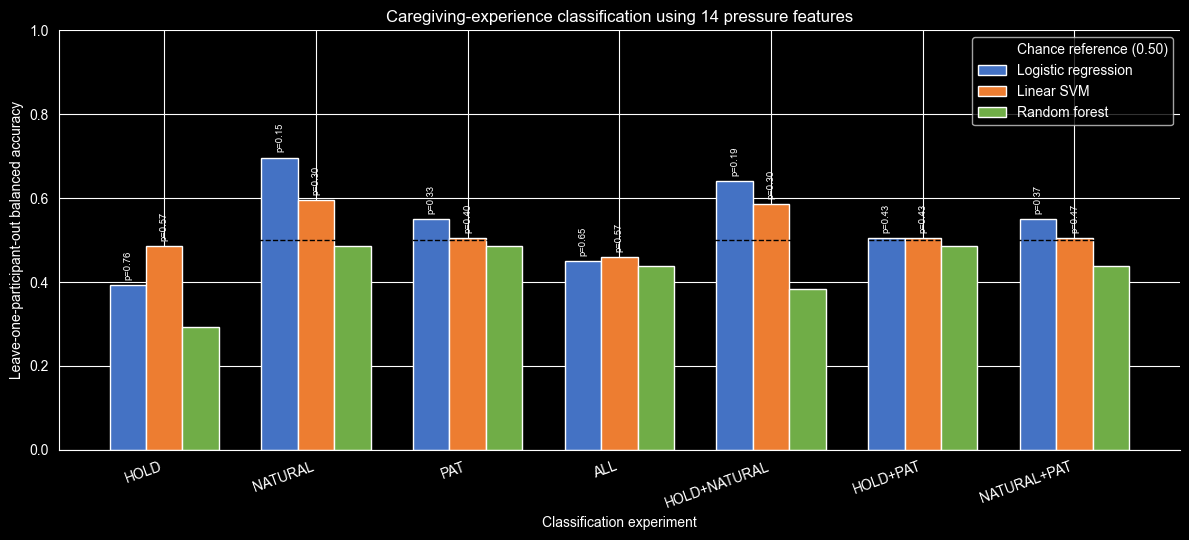

Saved: C:\Users\q8x7u\Documents\dissertation\Dissertation for job application\analysis\evaluation_outputs_svm\model_balanced_accuracy_with_svm.png


In [23]:
model_results = pd.read_csv(OUT_DIR / 'model_results.csv')
primary_results = model_results[model_results['analysis'] == 'primary_direct_labels'].copy()
setting_order = ['HOLD', 'NATURAL', 'PAT', 'ALL',
                 'HOLD+NATURAL', 'HOLD+PAT', 'NATURAL+PAT']
model_order = ['logistic', 'linear_svm', 'forest']
model_labels = {'logistic': 'Logistic regression',
                'linear_svm': 'Linear SVM', 'forest': 'Random forest'}
colours = {'logistic': '#4472C4', 'linear_svm': '#ED7D31', 'forest': '#70AD47'}

x = np.arange(len(setting_order))
width = 0.24
fig, ax = plt.subplots(figsize=(12, 5.5))
for offset, model_name in zip([-width, 0, width], model_order):
    subset = primary_results[primary_results['model'] == model_name]
    values = subset.set_index('setting').reindex(setting_order)['balanced_accuracy']
    bars = ax.bar(x + offset, values, width, label=model_labels[model_name],
                  color=colours[model_name])
    if model_name in ['logistic', 'linear_svm']:
        for bar, setting in zip(bars, setting_order):
            row = subset[subset['setting'] == setting]
            if not row.empty and not pd.isna(row.iloc[0].get('permutation_p', np.nan)):
                ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.012,
                        f"p={row.iloc[0]['permutation_p']:.2f}",
                        ha='center', va='bottom', fontsize=6.8, rotation=90)

ax.axhline(0.5, color='black', linestyle='--', linewidth=1, label='Chance reference (0.50)')
ax.set_ylim(0, 1)
ax.set_ylabel('Leave-one-participant-out balanced accuracy')
ax.set_xlabel('Classification experiment')
ax.set_title('Caregiving-experience classification using 14 pressure features')
ax.set_xticks(x)
ax.set_xticklabels(setting_order, rotation=20, ha='right')
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.legend(loc='upper right')
fig.tight_layout()
figure_path = OUT_DIR / 'model_balanced_accuracy_with_svm.png'
fig.savefig(figure_path, dpi=180, bbox_inches='tight')
plt.show()
print('Saved:', figure_path)


## 12. Evidence based conclusion

This section compares logistic regression, linear SVM and random forest across the same seven participant-separated experiments. Natural comforting remains the theoretically motivated primary experiment because it permits self-selected comforting strategies. A higher numerical score is not treated as reliable evidence unless uncertainty, permutation results and consistency across task settings also support it.


In [24]:
summary = primary_results.sort_values(['setting', 'balanced_accuracy'], ascending=[True, False])
display(summary[['setting', 'model', 'accuracy', 'balanced_accuracy', 'roc_auc',
                 'permutation_p', 'balanced_accuracy_ci95_bootstrap']])

print('=== Natural comforting comparison ===')
natural = primary_results[primary_results['setting'] == 'NATURAL'].copy()
for _, row in natural.sort_values('balanced_accuracy', ascending=False).iterrows():
    p_text = '' if pd.isna(row.get('permutation_p', np.nan)) else f", permutation p={row['permutation_p']:.3f}"
    print(f"{row['model']:12s}: accuracy={row['accuracy']:.3f}, "
          f"balanced accuracy={row['balanced_accuracy']:.3f}, "
          f"ROC AUC={row['roc_auc']:.3f}{p_text}")

print()
print('=== Evidence based interpretation ===')
best = natural.sort_values('balanced_accuracy', ascending=False).iloc[0]
if not pd.isna(best.get('permutation_p', np.nan)) and best['permutation_p'] < 0.05:
    print(f"The strongest natural-comforting model was {best['model']} and it exceeded the participant-label permutation threshold.")
else:
    print(f"The strongest natural-comforting model was {best['model']} numerically, but its permutation result did not establish reliable classification.")
print('Model comparisons are exploratory because there are only 20 independent participants.')


,setting,model,accuracy,balanced_accuracy,roc_auc,permutation_p,balanced_accuracy_ci95_bootstrap
10,ALL,linear_svm,0.45,0.459596,0.484848,0.567164,"[0.24747474747474746, 0.6717171717171717]"
9,ALL,logistic,0.45,0.449495,0.454545,0.651741,"[0.23737373737373738, 0.6616161616161615]"
11,ALL,forest,0.45,0.439394,0.393939,NaN,"[0.23737373737373738, 0.6414141414141414]"
1,HOLD,linear_svm,0.50,0.484848,0.363636,0.567164,"[0.2828282828282828, 0.696969696969697]"
0,HOLD,logistic,0.40,0.393939,0.272727,0.756219,"[0.1919191919191919, 0.606060606060606]"
2,HOLD,forest,0.30,0.292929,0.333333,NaN,"[0.10101010101010101, 0.4949494949494949]"
12,HOLD+NATURAL,logistic,0.65,0.641414,0.707071,0.189055,"[0.4292929292929293, 0.8434343434343434]"
13,HOLD+NATURAL,linear_svm,0.60,0.585859,0.656566,0.298507,"[0.3737373737373737, 0.7878787878787878]"
14,HOLD+NATURAL,forest,0.40,0.383838,0.303030,NaN,"[0.1919191919191919, 0.5858585858585859]"
15,HOLD+PAT,logistic,0.50,0.505051,0.353535,0.427861,"[0.29292929292929293, 0.7171717171717171]"


=== Natural comforting comparison ===
logistic    : accuracy=0.700, balanced accuracy=0.697, ROC AUC=0.717, permutation p=0.149
linear_svm  : accuracy=0.600, balanced accuracy=0.596, ROC AUC=0.646, permutation p=0.303
forest      : accuracy=0.500, balanced accuracy=0.485, ROC AUC=0.525

=== Evidence based interpretation ===
The strongest natural-comforting model was logistic numerically, but its permutation result did not establish reliable classification.
Model comparisons are exploratory because there are only 20 independent participants.


In [25]:
import numpy as np
from scipy.stats import ttest_rel, ttest_1samp

# --- Load participant-level predictions ---
predictions = pd.read_csv(OUT_DIR / 'participant_predictions.csv')

# --- Filter to natural soothing, primary labels ---
natural = predictions[
    (predictions['setting'] == 'NATURAL') &
    (predictions['analysis'] == 'primary_direct_labels')
].copy()

# --- Build participant-level correctness: 1 = correct, 0 = incorrect ---
natural['correct'] = (natural['true_label'] == natural['predicted_label']).astype(int)

# --- Pivot so each participant has one correctness value per model ---
wide = natural.pivot(index='participant', columns='model', values='correct')
print(wide)

lr_correct  = wide['logistic'].to_numpy()
svm_correct = wide['linear_svm'].to_numpy()

print(f"\nLogistic regression: {int(lr_correct.sum())} of {len(lr_correct)} correct")
print(f"Linear SVM:           {int(svm_correct.sum())} of {len(svm_correct)} correct")

# ============================================================
# TEST 1 — Paired t-test: logistic regression vs linear SVM
# ============================================================
print("\n=== Paired t-test: logistic regression vs linear SVM ===")

t_two, p_two = ttest_rel(lr_correct, svm_correct, alternative='two-sided')
print(f"Two-sided : t({len(lr_correct)-1}) = {t_two:.3f}, p = {p_two:.3f}")

t_one, p_one = ttest_rel(lr_correct, svm_correct, alternative='greater')
print(f"One-sided : t({len(lr_correct)-1}) = {t_one:.3f}, p = {p_one:.3f}   (tests: LR > SVM)")

# ============================================================
# TEST 2 — One-sample t-test: logistic regression vs 0.50 chance
# ============================================================
print("\n=== One-sample t-test: logistic regression vs 0.50 chance ===")

t_two_c, p_two_c = ttest_1samp(lr_correct, 0.5, alternative='two-sided')
print(f"Two-sided : t({len(lr_correct)-1}) = {t_two_c:.3f}, p = {p_two_c:.3f}")

t_one_c, p_one_c = ttest_1samp(lr_correct, 0.5, alternative='greater')
print(f"One-sided : t({len(lr_correct)-1}) = {t_one_c:.3f}, p = {p_one_c:.3f}   (tests: LR > chance)")

model        forest  linear_svm  logistic
participant                              
p01               0           1         1
p02               1           1         1
p03               0           0         0
p04               1           1         1
p05               0           1         1
p06               0           1         1
p07               1           1         1
p08               1           1         1
p09               0           0         0
p10               0           0         0
p11               0           0         1
p12               0           0         0
p13               1           0         0
p14               1           1         1
p15               0           0         0
p16               1           0         1
p17               1           1         1
p18               1           1         1
p19               0           1         1
p20               1           1         1

Logistic regression: 14 of 20 correct
Linear SVM:           12 of 20 correc